In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# 1. Data Understanding & EDA

In [2]:
df = pd.read_csv("healthcare_Stroke.csv")

In [3]:
df.shape

(5110, 12)

In [11]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
print("Target:\n", df["stroke"].value_counts())

Target:
 stroke
0    4861
1     249
Name: count, dtype: int64


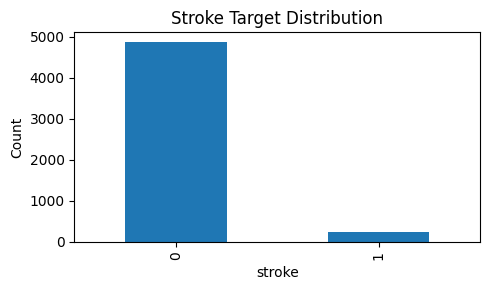

In [10]:
plt.figure(figsize=(5, 3))
df["stroke"].value_counts().plot(kind="bar")
plt.title("Stroke Target Distribution")
plt.xlabel("stroke")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 2. Data Cleaning & Feature Engineering

In [16]:
df = df.drop_duplicates().dropna(subset=["stroke"]).copy()
if "id" in df.columns:
    df = df.drop(columns=["id"])
df["age_glucose_ratio"] = df["age"] * df["avg_glucose_level"] / 100.0

# 3. Train/Test Split & Preprocessing Pipeline (no data leakage)

In [17]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [19]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

In [20]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

# 4. Models Comparison

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42)
}

In [22]:
results = []

In [23]:
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4)
    })

comp_df = pd.DataFrame(results).sort_values(by="F1", ascending=False)
display(comp_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,Decision Tree,0.9276,0.2143,0.18,0.1957,0.5730,0.0787
5,Naive Bayes,0.3160,0.0656,0.98,0.1230,0.7971,0.2013
3,Random Forest,0.9511,0.5000,0.04,0.0741,0.7791,0.1522
8,Extra Trees,0.9413,0.1429,0.04,0.0625,0.7395,0.1286
6,Gradient Boosting,0.9481,0.2000,0.02,0.0364,0.8320,0.2035
0,Logistic Regression,0.9511,0.0000,0.00,0.0000,0.8394,0.2677
1,KNN,0.9462,0.0000,0.00,0.0000,0.6146,0.0768
4,SVM,0.9511,0.0000,0.00,0.0000,0.6553,0.1358
7,AdaBoost,0.9511,0.0000,0.00,0.0000,0.8319,0.1936


# 5. GridSearchCV on Best Model (Training set only)

In [24]:
best_name = comp_df.iloc[0]["Model"]

best_f1_before = comp_df.iloc[0]["F1"]

param_grids = {
    "Random Forest": {"model__n_estimators": [100, 150], "model__max_depth": [None, 8, 12]},
    "Extra Trees": {"model__n_estimators": [100, 150], "model__max_depth": [None, 8, 12]},
    "Gradient Boosting": {"model__n_estimators": [100, 150], "model__learning_rate": [0.05, 0.1]},
    "Decision Tree": {"model__max_depth": [None, 5, 10], "model__min_samples_split": [2, 5]},
    "KNN": {"model__n_neighbors": [3, 5, 7]},
    "Logistic Regression": {"model__C": [0.1, 1.0, 10.0]},
    "SVM": {"model__C": [0.5, 1.0, 2.0]},
    "AdaBoost": {"model__n_estimators": [50, 100]},
    "Naive Bayes": {"model__var_smoothing": [1e-9, 1e-8]}
}

In [25]:
grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", models[best_name])]),
    param_grid=param_grids.get(best_name, {}),
    cv=5, scoring="f1", n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best Model:", best_name)
print("best_params_:", grid.best_params_)
print("best_score_:", round(grid.best_score_, 4))

Best Model: Decision Tree
best_params_: {'model__max_depth': None, 'model__min_samples_split': 2}
best_score_: 0.1528


# 6. Final Evaluation on Test Set & Plots

In [26]:
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]
print(f"F1 Before Tuning: {best_f1_before:.4f} | After Tuning: {f1_score(y_test, y_pred_best, zero_division=0):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

F1 Before Tuning: 0.1957 | After Tuning: 0.1957

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.96       972
           1       0.21      0.18      0.20        50

    accuracy                           0.93      1022
   macro avg       0.59      0.57      0.58      1022
weighted avg       0.92      0.93      0.92      1022



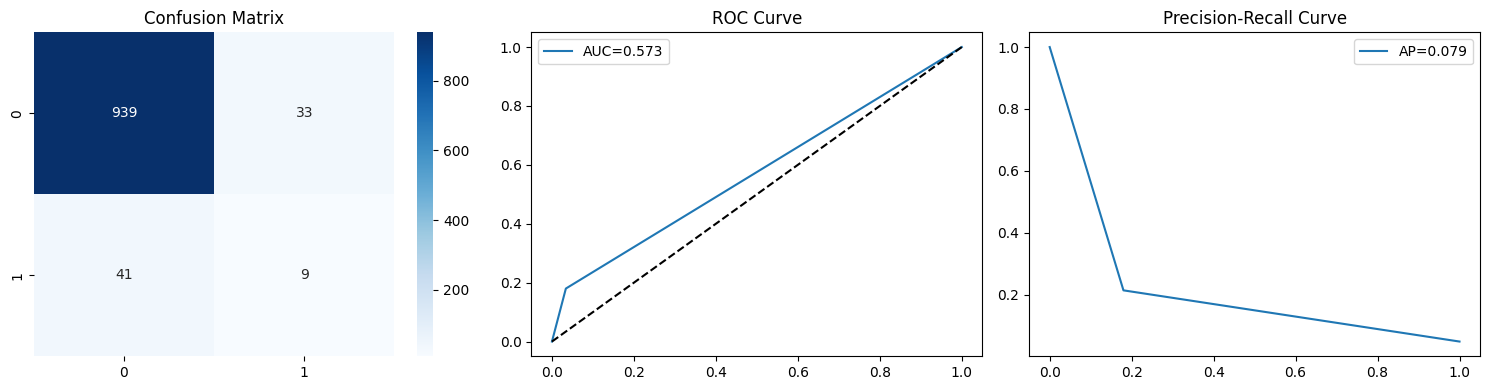

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob_best)
axes[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, y_prob_best):.3f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")
axes[1].legend()

prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob_best)
axes[2].plot(rec_c, prec_c, label=f"AP={average_precision_score(y_test, y_prob_best):.3f}")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend()
plt.tight_layout()
plt.show()

# 7. Deployment Artifacts (Saved Pipeline + Streamlit app.py + requirements.txt)

In [31]:
joblib.dump(best_model, "stroke_model_pipeline.joblib")

import streamlit as st
import pandas as pd
import joblib

st.title("Stroke Prediction App")
model = joblib.load("stroke_model_pipeline.joblib")

gender = st.selectbox("Gender", ["Male", "Female", "Other"])
age = st.number_input("Age", min_value=0.0, max_value=120.0, value=45.0)
hypertension = st.selectbox("Hypertension", [0, 1])
heart_disease = st.selectbox("Heart Disease", [0, 1])
ever_married = st.selectbox("Ever Married", ["Yes", "No"])
work_type = st.selectbox("Work Type", ["Private", "Self-employed", "Govt_job", "children", "Never_worked"])
residence_type = st.selectbox("Residence Type", ["Urban", "Rural"])
avg_glucose_level = st.number_input("Avg Glucose Level", min_value=40.0, max_value=400.0, value=100.0)
bmi = st.number_input("BMI", min_value=10.0, max_value=80.0, value=25.0)
smoking_status = st.selectbox("Smoking Status", ["never smoked", "formerly smoked", "smokes", "Unknown"])

if st.button("Predict"):
    row = pd.DataFrame([{
        "gender": gender, "age": age, "hypertension": hypertension,
        "heart_disease": heart_disease, "ever_married": ever_married,
        "work_type": work_type, "Residence_type": residence_type,
        "avg_glucose_level": avg_glucose_level, "bmi": bmi,
        "smoking_status": smoking_status,
        "age_glucose_ratio": age * avg_glucose_level / 100.0
    }])
    pred = model.predict(row)[0]
    prob = model.predict_proba(row)[0][1]
    st.success(f"Prediction: {'Stroke Risk (1)' if pred == 1 else 'No Stroke Risk (0)'} | Probability: {prob:.2%}")


2026-11-23 03:05:43.861 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.864 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.867 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.895 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.897 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.899 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.900 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-23 03:05:43.901 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar